# 12. Cointegração e causalidade de Granger

Segunda parte da modelagem econométrica (seções 6.2 e 6.3 do artigo). O notebook 11 mostrou que as quatro séries em log são I(1) e que, em primeira diferença, quase não há correlação. Mas **diferenciar pode apagar uma relação de longo prazo**: se duas séries I(1) compartilham uma tendência comum (cointegração), uma combinação linear delas é estacionária, e a correlação em Δ parece zero mesmo havendo ligação. Por isso, antes do Granger, testa-se a cointegração.

**Roteiro**

1. Engle-Granger nos 6 pares (120 meses).
2. Johansen nos sistemas de 3 e de 4 séries, com 7 valores de defasagem, com e sem tendência linear, com e sem sazonalidade removida.
3. Granger em um VAR de primeiras diferenças dos logs, 12 pares direcionados, 1 a 6 defasagens.
4. Verificações: autocorrelação dos resíduos, Toda e Yamamoto em nível e Granger sem o crédito.

**O que este notebook não é.** É modelagem econométrica de séries temporais para inferir associação e precedência, não aprendizado de máquina: não há treino nem teste, e as especificações são comparadas por testes de hipótese e por AIC/BIC. Granger mede se o passado de uma série melhora a previsão de outra. **Isso é previsão, não causalidade.**

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')

# lê os arquivos da pasta local do repositório quando ela existe; senão, direto do GitHub
RAIZ = 'https://raw.githubusercontent.com/vicleme/port-of-santos-credit-fx/refs/heads/main/'

def ler(caminho, **kw):
    local = os.path.join('..', caminho)
    return pd.read_csv(local if os.path.exists(local) else RAIZ + caminho, **kw)

def fmt(x, casas=2):
    """número com vírgula decimal"""
    return f'{x:.{casas}f}'.replace('.', ',')

def fmtp(p):
    """p-valor no estilo do artigo"""
    return '<0,0001' if p < 0.0001 else fmt(p, 4)

from itertools import combinations
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from statsmodels.tsa.api import VAR

painel = ler('data/processed/painel_modelagem_2015_2025.csv')
painel['data'] = pd.to_datetime(dict(year=painel['ano'], month=painel['mes'], day=1))
painel = painel.set_index('data').asfreq('MS')   # frequência mensal explícita (evita avisos do statsmodels)

# nomes curtos usados nas tabelas: câmbio, crédito (sem o Bradesco), exportação e importação (valor)
logs = pd.DataFrame({
    'câmbio': np.log(painel['cambio_venda']),
    'crédito': np.log(painel['credito_ex_bradesco']),
    'exportação': np.log(painel['exportação_fob']),
    'importação': np.log(painel['importação_fob']),
})
L120 = logs.dropna()                              # jan/2015 a dez/2024
L132 = logs[['câmbio', 'exportação', 'importação']]  # jan/2015 a dez/2025, sem crédito
print(f'4 séries: {len(L120)} meses | 3 séries: {len(L132)} meses')

4 séries: 120 meses | 3 séries: 132 meses


## 1. Engle-Granger nos seis pares

Regride-se uma série na outra e testa-se se o resíduo é estacionário (hipótese nula: **não** há cointegração). Constante e defasagens pelo AIC; o valor crítico a 5% é de cerca de -3,39. Limiar de Bonferroni para seis pares: p < 0,0083.

O teste não é simétrico (depende de qual série é a dependente), então a tabela traz também a ordem inversa como verificação.

In [2]:
linhas = []
for a, b in combinations(L120.columns, 2):
    est, pv, crit = coint(L120[a], L120[b], trend='c', autolag='aic')
    est_i, pv_i, _ = coint(L120[b], L120[a], trend='c', autolag='aic')
    linhas.append({'par': f'{a} × {b}', 'estatística': est, 'crítico 5%': crit[1], 'p-valor': pv,
                   'cointegradas?': 'Sim' if pv < 0.05 else 'Não', 'p (ordem inversa)': pv_i})
tabela4 = pd.DataFrame(linhas)
display(tabela4.round(4))

,par,estatística,crítico 5%,p-valor,cointegradas?,p (ordem inversa)
0,câmbio × crédito,-2.2355,-3.388,0.4061,Não,0.8521
1,câmbio × exportação,-3.1488,-3.388,0.0789,Não,0.5134
2,câmbio × importação,-1.3080,-3.388,0.8273,Não,0.2235
3,crédito × exportação,-1.3462,-3.388,0.8154,Não,0.4745
4,crédito × importação,-1.5247,-3.388,0.7516,Não,0.0963
5,exportação × importação,-1.9286,-3.388,0.5654,Não,0.1897


Nenhum par rejeita a ausência de cointegração. O mais próximo é câmbio × exportação (p = 0,079, e na ordem inversa p = 0,51). Exportação × importação, com correlação em nível de 0,79, também não é cointegrada: **correlação alta em nível não indicava relação de longo prazo**.

## 2. Johansen

O teste de Johansen examina o sistema inteiro. Estatística do traço contra o valor crítico de 5%, para a hipótese de nenhuma relação de cointegração (r = 0) e de no máximo uma (r ≤ 1).

**Duas decisões que mudam o resultado:**

- **Termo determinístico:** só constante (`det_order = 0`), ou constante e tendência linear (`det_order = 1`).
- **Sazonalidade:** a exportação tem sazonalidade forte, que o teste não modela e que tende a inflar a rejeição. Por isso o teste é feito também com a sazonalidade mensal removida (subtrai-se de cada série a média do seu mês do calendário, e soma-se a média geral).

Defasagens k = 1, 2, 3, 4, 6, 8 e 12; o que se conta é em quantas das 7 especificações a hipótese é rejeitada.

In [3]:
def sem_sazonalidade(df):
    out = df.copy()
    for c in df.columns:
        out[c] = df[c] - df[c].groupby(df.index.month).transform('mean') + df[c].mean()
    return out

KS = [1, 2, 3, 4, 6, 8, 12]
sistemas = [('3 séries (132 meses)', L132), ('4 séries (120 meses)', L120)]
linhas, detalhe = [], {}
for nome_sis, base in sistemas:
    for nome_serie, dados in [('bruta', base), ('sem sazonalidade', sem_sazonalidade(base))]:
        for det, nome_det in [(0, 'constante'), (1, 'constante e tendência')]:
            rej0, rej1, ks_rej = 0, 0, []
            for k in KS:
                r = coint_johansen(dados.values, det_order=det, k_ar_diff=k)
                a, b = r.lr1[0] > r.cvt[0, 1], r.lr1[1] > r.cvt[1, 1]
                rej0 += a; rej1 += b
                if a: ks_rej.append(k)
            linhas.append({'sistema': nome_sis, 'série': nome_serie, 'termo determinístico': nome_det,
                           'rejeita r = 0': f'{rej0} de 7', 'rejeita r ≤ 1': f'{rej1} de 7'})
            detalhe[(nome_sis, nome_serie, nome_det)] = ks_rej
tabela5 = pd.DataFrame(linhas)
display(tabela5)
print('defasagens em que r = 0 é rejeitado, sistema de 4 séries sem sazonalidade, com tendência:',
      detalhe[('4 séries (120 meses)', 'sem sazonalidade', 'constante e tendência')])

,sistema,série,termo determinístico,rejeita r = 0,rejeita r ≤ 1
0,3 séries (132 meses),bruta,constante,5 de 7,0 de 7
1,3 séries (132 meses),bruta,constante e tendência,6 de 7,4 de 7
2,3 séries (132 meses),sem sazonalidade,constante,1 de 7,0 de 7
3,3 séries (132 meses),sem sazonalidade,constante e tendência,6 de 7,1 de 7
4,4 séries (120 meses),bruta,constante,6 de 7,0 de 7
5,4 séries (120 meses),bruta,constante e tendência,7 de 7,0 de 7
6,4 séries (120 meses),sem sazonalidade,constante,1 de 7,0 de 7
7,4 séries (120 meses),sem sazonalidade,constante e tendência,2 de 7,1 de 7


defasagens em que r = 0 é rejeitado, sistema de 4 séries sem sazonalidade, com tendência: [8, 12]


**Leitura.** O resultado muda com o termo determinístico e com o tratamento da sazonalidade:

- Com as séries brutas, rejeita-se quase sempre, mas a sazonalidade da exportação infla essa rejeição.
- Sem sazonalidade e só com constante, a rejeição quase desaparece (1 de 7 nos dois sistemas).
- Com tendência linear, ela persiste no sistema câmbio, exportação e importação (6 de 7), mas **não** no sistema com o crédito (2 de 7, apenas com 8 e 12 defasagens).

Como o Engle-Granger não encontra nenhum par e o Johansen depende da especificação, **a cointegração não está estabelecida de forma robusta**. Isso não prova que não exista relação de longo prazo entre câmbio, exportação e importação (o Johansen com tendência linear a sugere), mas nenhuma evidência envolve o crédito. Por isso o Granger principal usa primeiras diferenças, com verificação em nível pelo procedimento de Toda e Yamamoto, que vale com ou sem cointegração.

## 3. Granger em primeiras diferenças dos logs

VAR com as quatro séries em Δ log (119 observações) e variáveis binárias mensais (11 meses) para a sazonalidade. Para cada par direcionado, testa-se se **todas** as defasagens da série "causadora" são nulas na equação da outra (teste F). São 12 pares, então o limiar de Bonferroni é 0,05/12 ≈ 0,0042.

Primeiro, a escolha do número de defasagens por critério de informação:

In [4]:
D = L120.diff().dropna()
meses = pd.get_dummies(D.index.month, prefix='m', drop_first=True, dtype=float).set_axis(D.index, axis=0)
print(f'observações em Δ log: {len(D)} | binárias mensais: {meses.shape[1]}')

ordem = VAR(D, exog=meses).select_order(6, trend='c')
print('defasagem escolhida:', {k: int(v) for k, v in ordem.selected_orders.items() if k in ('aic', 'bic')})

observações em Δ log: 119 | binárias mensais: 11
defasagem escolhida: {'aic': 4, 'bic': 1}


In [5]:
LAGS = range(1, 7)
pares = [(c, e) for c in D.columns for e in D.columns if c != e]
grade = pd.DataFrame(index=[f'{c} → {e}' for c, e in pares], columns=list(LAGS), dtype=float)
for k in LAGS:
    m = VAR(D, exog=meses).fit(k, trend='c')
    for c, e in pares:
        grade.loc[f'{c} → {e}', k] = m.test_causality(e, [c], kind='f').pvalue

display(grade.round(3))
print('\npares com p < 0,05, por número de defasagens:')
for k in LAGS:
    print(k, '->', [par for par in grade.index if grade.loc[par, k] < 0.05] or 'nenhum')
print(f'\nesperado por acaso em 12 testes a 5%: {12 * 0.05:.1f} por especificação | passam em Bonferroni (p < {0.05/12:.4f}):',
      [(par, k) for par in grade.index for k in LAGS if grade.loc[par, k] < 0.05 / 12] or 'nenhum')

,1,2,3,4,5,6
câmbio → crédito,0.218,0.517,0.689,0.760,0.836,0.902
câmbio → exportação,0.182,0.127,0.037,0.063,0.110,0.161
câmbio → importação,0.168,0.101,0.072,0.037,0.122,0.241
crédito → câmbio,0.573,0.952,0.841,0.845,0.831,0.773
crédito → exportação,0.683,0.547,0.608,0.246,0.716,0.717
crédito → importação,0.549,0.272,0.456,0.577,0.735,0.883
exportação → câmbio,0.004,0.045,0.134,0.181,0.316,0.047
exportação → crédito,0.377,0.208,0.184,0.074,0.141,0.175
exportação → importação,0.481,0.564,0.275,0.232,0.518,0.472
importação → câmbio,0.453,0.708,0.718,0.667,0.744,0.603



pares com p < 0,05, por número de defasagens:
1 -> ['exportação → câmbio']
2 -> ['exportação → câmbio']
3 -> ['câmbio → exportação']
4 -> ['câmbio → importação']
5 -> nenhum
6 -> ['exportação → câmbio']

esperado por acaso em 12 testes a 5%: 0.6 por especificação | passam em Bonferroni (p < 0.0042): [('exportação → câmbio', 1)]


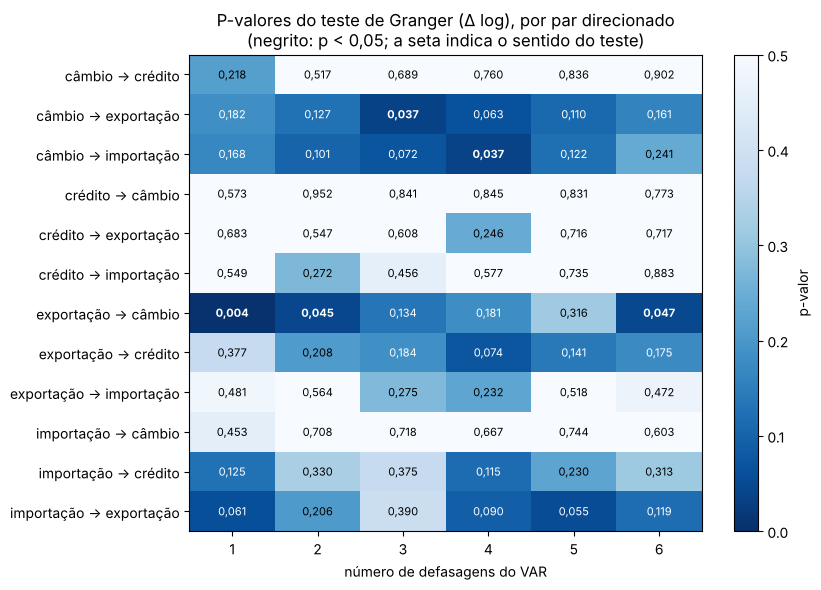

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 6))
im = ax.imshow(grade.values, cmap='Blues_r', vmin=0, vmax=0.5, aspect='auto')
ax.set_xticks(range(len(LAGS))); ax.set_xticklabels(list(LAGS))
ax.set_yticks(range(len(grade))); ax.set_yticklabels(grade.index)
ax.set_xlabel('número de defasagens do VAR')
for i in range(grade.shape[0]):
    for j in range(grade.shape[1]):
        v = grade.values[i, j]
        ax.text(j, i, fmt(v, 3), ha='center', va='center', fontsize=8,
                color='white' if v < 0.2 else 'black', fontweight='bold' if v < 0.05 else 'normal')
ax.set_title('P-valores do teste de Granger (Δ log), por par direcionado\n(negrito: p < 0,05; a seta indica o sentido do teste)')
fig.colorbar(im, ax=ax, label='p-valor')
plt.tight_layout()
plt.show()

**Leitura.** Não há precedência preditiva estável:

- Em cada número de defasagens há no máximo um par com p < 0,05, e o crédito não aparece em nenhum par com p < 0,05.
- O câmbio ajuda a prever a exportação com 3 defasagens (p = 0,037) e a importação com 4 (p = 0,037), mas não nas demais, e nenhum passa em Bonferroni.
- O resultado mais recorrente é **o inverso da hipótese do trabalho**: a exportação ajuda a prever o câmbio (p = 0,004 com 1 defasagem, 0,045 com 2 e 0,047 com 6). Só com 1 defasagem passa em Bonferroni, mas esse VAR deixa autocorrelação nos resíduos (seção 4).

## 4. Autocorrelação dos resíduos

Um VAR com poucas defasagens pode deixar autocorrelação nos resíduos, e os p-valores do Granger deixam de ser confiáveis. Teste de Portmanteau (autocorrelação conjunta dos resíduos) com 12 defasagens além das do modelo (h = k + 12), sem ajuste de amostra pequena. Hipótese nula: resíduos sem autocorrelação.

In [7]:
linhas = []
for k in LAGS:
    m = VAR(D, exog=meses).fit(k, trend='c')
    linhas.append({'defasagens': k, 'Portmanteau (h = k + 12), p': m.test_whiteness(nlags=k + 12, adjusted=False).pvalue,
                   'exportação → câmbio, p': grade.loc['exportação → câmbio', k]})
display(pd.DataFrame(linhas).round(3))

,defasagens,"Portmanteau (h = k + 12), p","exportação → câmbio, p"
0,1,0.039,0.004
1,2,0.291,0.045
2,3,0.606,0.134
3,4,0.737,0.181
4,5,0.254,0.316
5,6,0.049,0.047


Com 1 defasagem (a escolha do BIC), os resíduos têm autocorrelação (p ≈ 0,04), o que **enfraquece justamente o resultado mais forte** (exportação → câmbio, p = 0,004). Com 4 defasagens (a escolha do AIC), os resíduos não têm autocorrelação (p ≈ 0,74) e o resultado desaparece (p = 0,18).

## 5. Verificação em nível: Toda e Yamamoto

O Granger em Δ pressupõe que diferenciar é adequado. O procedimento de Toda e Yamamoto (1995) estima o VAR **em nível** com p + 1 defasagens (1 a mais, porque as séries são I(1)) e testa apenas as p primeiras: vale com ou sem cointegração. Aqui cada equação é estimada por mínimos quadrados e o teste é o Wald (qui-quadrado) das p primeiras defasagens da série causadora.

In [8]:
def desenho(Y, k):
    cols = {f'{c}_L{j}': Y[c].shift(j) for j in range(1, k + 1) for c in Y.columns}
    Z = pd.concat([pd.DataFrame(cols, index=Y.index),
                   pd.get_dummies(Y.index.month, prefix='m', drop_first=True, dtype=float).set_axis(Y.index, axis=0)], axis=1)
    Z['const'] = 1.0
    return Z.iloc[k:], Y.iloc[k:]

def wald_p(Y, causa, efeito, p, n_defas):
    """p-valor Wald (qui-quadrado) de que as p primeiras defasagens de `causa` são nulas na equação de `efeito`"""
    Z, Yk = desenho(Y, n_defas)
    m = sm.OLS(Yk[efeito], Z).fit()
    R = np.zeros((p, Z.shape[1]))
    for j in range(1, p + 1):
        R[j - 1, list(Z.columns).index(f'{causa}_L{j}')] = 1
    return float(m.wald_test(R, use_f=False, scalar=True).pvalue)

ty = pd.DataFrame(index=grade.index, columns=list(LAGS), dtype=float)
for k in LAGS:
    for c, e in pares:
        ty.loc[f'{c} → {e}', k] = wald_p(L120, c, e, k, k + 1)
display(ty.round(3))
print('pares com p < 0,05:', [(par, k) for par in ty.index for k in LAGS if ty.loc[par, k] < 0.05] or 'nenhum')
print('pares com o crédito e p < 0,05:', [(par, k) for par in ty.index if 'crédito' in par for k in LAGS if ty.loc[par, k] < 0.05] or 'nenhum')

,1,2,3,4,5,6
câmbio → crédito,0.382,0.477,0.550,0.921,0.877,0.919
câmbio → exportação,0.027,0.039,0.066,0.082,0.128,0.195
câmbio → importação,0.312,0.220,0.239,0.217,0.411,0.634
crédito → câmbio,0.550,0.903,0.770,0.833,0.773,0.781
crédito → exportação,0.481,0.558,0.688,0.372,0.706,0.795
crédito → importação,0.605,0.285,0.452,0.608,0.811,0.866
exportação → câmbio,0.007,0.051,0.145,0.154,0.228,0.035
exportação → crédito,0.527,0.366,0.155,0.127,0.163,0.221
exportação → importação,0.515,0.847,0.552,0.637,0.680,0.597
importação → câmbio,0.235,0.543,0.644,0.431,0.474,0.301


pares com p < 0,05: [('câmbio → exportação', 1), ('câmbio → exportação', 2), ('exportação → câmbio', 1), ('exportação → câmbio', 6), ('importação → exportação', 1), ('importação → exportação', 4), ('importação → exportação', 5)]
pares com o crédito e p < 0,05: nenhum


Em nível, o quadro é de sinais fracos e esporádicos: exportação → câmbio reaparece (p = 0,007 com 1 defasagem e 0,035 com 6), câmbio → exportação tem p = 0,027 e 0,039 com 1 e 2 defasagens e 0,066 a 0,195 nas demais, e **o crédito não aparece em nenhum par**.

Um resultado que a tabela traz e que **não é sobre câmbio nem crédito**: importação → exportação tem p < 0,05 em 3 das 6 especificações (0,006 com 1 defasagem, 0,013 com 4 e 0,019 com 5). Nenhuma passa no limiar de Bonferroni de 0,0042, mas é o par mais recorrente em nível e é coerente com a correlação exportação × importação do notebook 11 (a hipótese dos fatores de calendário, ainda não testada). Em Δ, o mesmo par fica perto do limite (p entre 0,055 e 0,39).

## 6. Granger sem o crédito

Sem o crédito, a amostra cresce (132 meses, 131 em Δ) e o sistema tem três séries. Se o efeito do câmbio sobre a exportação dependesse de o crédito estar no modelo, ele apareceria aqui mais claramente; se ele sumir, era frágil.

In [9]:
D3 = L132.diff().dropna()
meses3 = pd.get_dummies(D3.index.month, prefix='m', drop_first=True, dtype=float).set_axis(D3.index, axis=0)
linhas = []
for k in LAGS:
    m = VAR(D3, exog=meses3).fit(k, trend='c')
    linhas.append({'defasagens': k, 'câmbio → exportação': m.test_causality('exportação', ['câmbio'], kind='f').pvalue,
                   'câmbio → importação': m.test_causality('importação', ['câmbio'], kind='f').pvalue,
                   'exportação → câmbio': m.test_causality('câmbio', ['exportação'], kind='f').pvalue})
sem_credito = pd.DataFrame(linhas)
display(sem_credito.round(3))
print(f'observações em Δ: {len(D3)}')

,defasagens,câmbio → exportação,câmbio → importação,exportação → câmbio
0,1,0.202,0.121,0.011
1,2,0.159,0.096,0.084
2,3,0.092,0.038,0.179
3,4,0.232,0.016,0.312
4,5,0.376,0.048,0.383
5,6,0.436,0.113,0.139


observações em Δ: 131


Sem o crédito, o câmbio deixa de ajudar a prever a **exportação** (p entre 0,09 e 0,44). O resultado de 3 defasagens do VAR de quatro séries não sobrevive à mudança de amostra e de sistema.

Para a **importação** o quadro é outro: o câmbio passa a ajudar a prever a importação em 3 das 6 especificações (p = 0,038 com 3 defasagens, 0,016 com 4 e 0,048 com 5). Nenhuma passa no limiar de Bonferroni para este sistema (6 pares direcionados, 0,05/6 ≈ 0,0083), e é um resultado que depende da amostra maior e do sistema sem crédito, mas **não se pode descrever como ausência total de sinal**: é o resultado do câmbio sobre a carga mais próximo de se repetir entre especificações.

## Conclusões e limites

1. **Cointegração não estabelecida de forma robusta.** Engle-Granger: nenhum par. Johansen: sensível ao termo determinístico e à sazonalidade, e sem rejeição robusta no sistema com crédito.
2. **Sem precedência preditiva estável, com uma ressalva.** O crédito não aparece em nenhum par com p < 0,05, em Δ ou em nível. O câmbio ajuda a prever exportação e importação em uma ou duas especificações do VAR de quatro séries, sem passar em Bonferroni; no sistema sem crédito, o câmbio → importação aparece em 3 de 6 especificações (p entre 0,016 e 0,048), também sem passar em Bonferroni. O resultado mais recorrente (exportação → câmbio) é o inverso da hipótese e depende de um VAR com autocorrelação residual.
3. **Granger é previsão, não causalidade.** Ausência de resultado também não prova ausência de efeito: com 120 observações, quatro séries e sazonalidade, o poder estatístico é limitado; os resíduos não são normais (valores extremos como set/out de 2021); e o efeito pode ser não linear ou concentrado em períodos curtos, como 2020.
4. **Próximos passos:** modelo de correção de erro para câmbio, exportação e importação se a cointegração se confirmar; Granger por subperíodos (antes e depois de 2020) e com os valores em peso (kg).